C:\Users\HP\AppData\Local\Temp\ipykernel_6732\1056181185.py:15: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  for col in df.select_dtypes(include='object').columns:


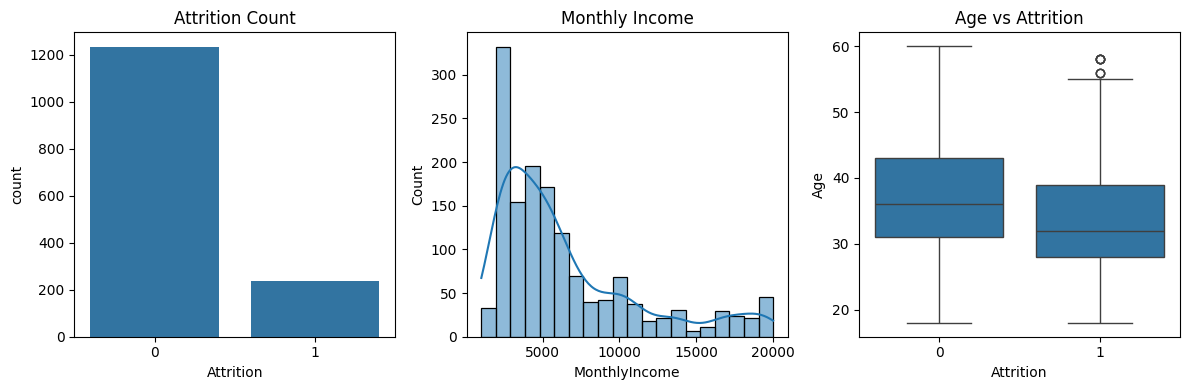


========== Logistic Regression ==========
Accuracy: 0.8741
F1-Score: 0.4932
[[239   8]
 [ 29  18]]
              precision    recall  f1-score   support

           0       0.89      0.97      0.93       247
           1       0.69      0.38      0.49        47

    accuracy                           0.87       294
   macro avg       0.79      0.68      0.71       294
weighted avg       0.86      0.87      0.86       294



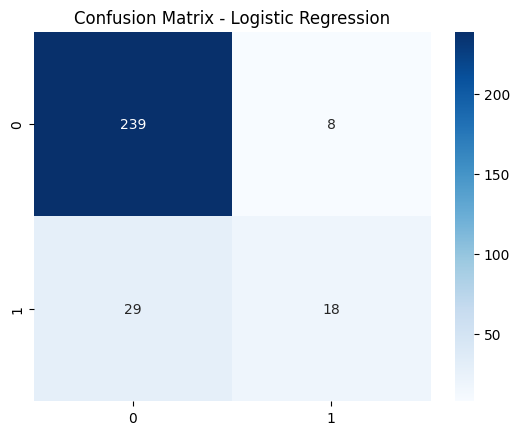


========== Decision Tree ==========
Accuracy: 0.8435
F1-Score: 0.2812
[[239   8]
 [ 38   9]]
              precision    recall  f1-score   support

           0       0.86      0.97      0.91       247
           1       0.53      0.19      0.28        47

    accuracy                           0.84       294
   macro avg       0.70      0.58      0.60       294
weighted avg       0.81      0.84      0.81       294



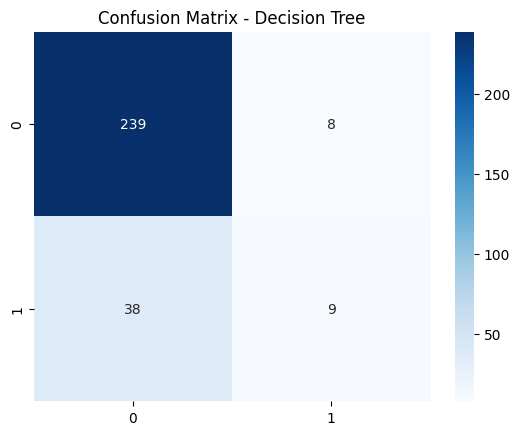


========== Random Forest ==========
Accuracy: 0.8435
F1-Score: 0.2069
[[242   5]
 [ 41   6]]
              precision    recall  f1-score   support

           0       0.86      0.98      0.91       247
           1       0.55      0.13      0.21        47

    accuracy                           0.84       294
   macro avg       0.70      0.55      0.56       294
weighted avg       0.81      0.84      0.80       294



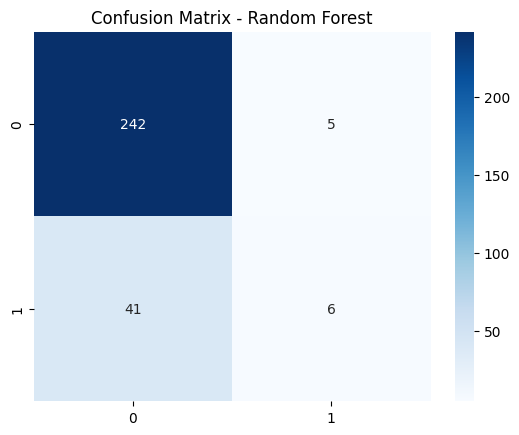

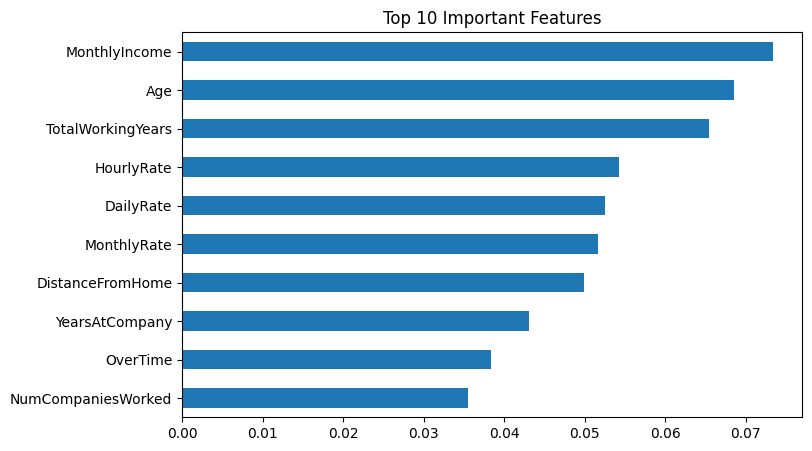

MonthlyIncome         0.073336
Age                   0.068557
TotalWorkingYears     0.065480
HourlyRate            0.054217
DailyRate             0.052526
MonthlyRate           0.051631
DistanceFromHome      0.049930
YearsAtCompany        0.043107
OverTime              0.038350
NumCompaniesWorked    0.035546
dtype: float64


In [18]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder, StandardScaler
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report, f1_score

data = pd.read_csv('WA_Fn-UseC_-HR-Employee-Attrition.csv')
df = data.drop(['EmployeeCount', 'EmployeeNumber', 'Over18', 'StandardHours'], axis=1)

for col in df.select_dtypes(include='object').columns:
    if col!= 'Attrition':
        df[col] = LabelEncoder().fit_transform(df[col])

df['Attrition'] = df['Attrition'].map({'Yes': 1, 'No': 0})

plt.figure(figsize=(12,4))
plt.subplot(1,3,1)
sns.countplot(x='Attrition', data=df)
plt.title('Attrition Count')

plt.subplot(1,3,2)
sns.histplot(df['MonthlyIncome'], kde=True)
plt.title('Monthly Income')

plt.subplot(1,3,3)
sns.boxplot(x='Attrition', y='Age', data=df)
plt.title('Age vs Attrition')
plt.tight_layout()
plt.show()

X = df.drop('Attrition', axis=1)
y = df['Attrition']
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)

scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

lr = LogisticRegression(max_iter=1000)
lr.fit(X_train_scaled, y_train)
pred_lr = lr.predict(X_test_scaled)

dt = DecisionTreeClassifier(random_state=42, max_depth=5)
dt.fit(X_train, y_train)
pred_dt = dt.predict(X_test)

rf = RandomForestClassifier(n_estimators=100, random_state=42)
rf.fit(X_train, y_train)
pred_rf = rf.predict(X_test)

def evaluate_model(name, y_true, y_pred):
    print(f"\n========== {name} ==========")
    print(f"Accuracy: {accuracy_score(y_true, y_pred):.4f}")
    print(f"F1-Score: {f1_score(y_true, y_pred):.4f}")
    print(confusion_matrix(y_true, y_pred))
    print(classification_report(y_true, y_pred))
    sns.heatmap(confusion_matrix(y_true, y_pred), annot=True, fmt='d', cmap='Blues')
    plt.title(f'Confusion Matrix - {name}')
    plt.show()

evaluate_model("Logistic Regression", y_test, pred_lr)
evaluate_model("Decision Tree", y_test, pred_dt)
evaluate_model("Random Forest", y_test, pred_rf)

importances = pd.Series(rf.feature_importances_, index=X.columns).sort_values(ascending=False).head(10)
plt.figure(figsize=(8,5))
importances.plot(kind='barh')
plt.gca().invert_yaxis()
plt.title('Top 10 Important Features')
plt.show()
print(importances)